# Multichannel EEG: threshold first


In [1]:
# Run all cells in order. Synthetic EEG, not experimental validation.
# No plugin installation needed; source is loaded from this repository.
from pathlib import Path
from dataclasses import replace
import sys
import numpy as np
import matplotlib.pyplot as plt

candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent / 'src', parent / 'PythonPlugin' / 'src',
                       parent / 'scripts' / 'PythonPlugin' / 'src'])
plugin_src = next((p for p in candidates if (p/'windowed_detrend/__init__.py').is_file()), None)
if plugin_src is None:
    raise FileNotFoundError('Start inside the windowedDetrend repository')
sys.path[:0] = [str(plugin_src), str(plugin_src.parent)]
from windowed_detrend import Config, detrend
from demo_multichannel_data import make_demo_eeg

## A. Controls in order of importance


In [2]:
cfg = Config(
    # 1. Slope Threshold: main decision parameter for extreme-artifact detection.
    # A channel score >= threshold is classified as extreme: enable windowed fits.
    # Threshold above ALL channel scores: apply the basic whole-epoch linear fit.
    # Scores are absolute epoch-mean standardized slopes. Lower => more flagged.
    slope_threshold=0.5,
    # 2. Peak search interval (seconds relative to the recorded TMS trigger).
    # The detected peak splits rise/decay; slopes use pre, rise AND decay.
    onset_s=0.0,
    peak_search_end_s=0.020,
    # 3. Models, kept at the published Windowed TEP defaults.
    pre_degree=2,
    rise_model='lagrange',  # Interpolates every rise sample; degree N-1.
    decay_model='poly',
    decay_degree=3,        # Offset channels: cubic; others: degree 2.
    fill_mode='gaussian',  # Default: replace the zeroed rise plus margin with Gaussian noise.
)
# All other fields keep their library defaults: channel_policy='auto',
# constrain_decay=False, only_offset_channels=False, overall_degree=1.
# No flagged channel => whole-epoch linear fit, no Lagrange and no filling.
# At least one flagged => windowed fits on ALL selected channels by default.
# Changing cfg does not change the synthetic data below.

## B. Synthetic EEG: channels, stimuli and jitter


In [3]:
toy = dict(n_epochs=12, n_channels=16, fs_hz=2000, seed=42,
           stimulus_jitter_s=0.0007,  # Common latency shift per stimulus: +/-0.7 ms.
           channel_jitter_s=0.00035,  # Additional latency per channel: +/-0.35 ms.
           amplitude_jitter=0.10,    # Artifact amplitude varies +/-10% per trace.
           noise_sd=0.05)           # Independent background noise, arbitrary units.
data, times, truth, artifact, metadata = make_demo_eeg(**toy)
labels = metadata['channel_labels']
# Two channels have stronger artifacts, with weaker contamination elsewhere.
# A damped response and ongoing background provide known clean ground truth.
# Jitter changes signal latency relative to fixed event markers at t=0;
# it does not resample the epochs or introduce the removed pulse artifact.
print('Input shape (epochs, channels, samples):', data.shape)
print('Stimulus jitter (ms):', np.round(1000*metadata['stimulus_jitter_s'], 3))

Input shape (epochs, channels, samples): (12, 16, 700)
Stimulus jitter (ms): [-0.436 -0.247 -0.555  0.43   0.048  0.482  0.332 -0.59   0.055 -0.517
  0.508 -0.05 ]


## 1. Apply automatic screening and Polynomial detrending


In [4]:
corrected, trend, diagnostics = detrend(data, times, cfg)
selection = diagnostics['channel_selection']
scores = np.max(np.abs(np.asarray(selection['mean_z'])), axis=1)
offset_channels = selection['offset_channels']
operation = diagnostics['operation']
mask = times >= 0
mse_full = float(np.mean((corrected[:, :, mask]-truth[:, :, mask])**2))
print('Operation:', operation)
print('Offset channels:', [labels[c] for c in offset_channels])
print('Channel  max|mean z-slope|  classification')
for c, label in enumerate(labels):
    print(f'{label:7s}  {scores[c]:8.4f}          {"offset" if c in offset_channels else "below threshold"}')
print(f'Post-trigger recovery MSE: {mse_full:.6f} a.u.^2')
# Inspect operation before accessing rise/decay: fallback records have overall.
if operation == 'windowed':
    print('Decay degree by channel:', [r['decay']['degree'] for r in diagnostics['fits'] if r['epoch']==0])
else:
    print('No windowed detrending: whole-epoch linear fit; no gap filling.')

Operation: windowed
Offset channels: ['EEG01', 'EEG02']
Channel  max|mean z-slope|  classification
EEG01      2.9376          offset
EEG02      2.3396          offset
EEG03      0.3898          below threshold
EEG04      0.4156          below threshold
EEG05      0.4096          below threshold
EEG06      0.3591          below threshold
EEG07      0.3631          below threshold
EEG08      0.3617          below threshold
EEG09      0.3699          below threshold
EEG10      0.3684          below threshold
EEG11      0.3756          below threshold
EEG12      0.3938          below threshold
EEG13      0.3850          below threshold
EEG14      0.3909          below threshold
EEG15      0.3863          below threshold
EEG16      0.3692          below threshold
Post-trigger recovery MSE: 0.247446 a.u.^2
Decay degree by channel: [3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


## 2. Change only the threshold on the SAME data


In [5]:
# This sweep illustrates decisions; it does not optimize the threshold.
sweep_thresholds = np.unique(np.r_[.25, .5, 1., 2., 3., cfg.slope_threshold])
sweep_counts = []
sweep_operations = []
sweep_mse = []
print('Threshold  flagged channels  operation             recovery MSE')
for threshold in sweep_thresholds:
    sweep_output, _, sweep_info = detrend(data, times, replace(cfg, slope_threshold=float(threshold)))
    count = len(sweep_info['channel_selection']['offset_channels'])
    error = float(np.mean((sweep_output[:, :, mask]-truth[:, :, mask])**2))
    sweep_counts.append(count); sweep_operations.append(sweep_info['operation']); sweep_mse.append(error)
    print(f'{threshold:8.3f}  {count:16d}  {sweep_info["operation"]:20s}  {error:.6f}')

Threshold  flagged channels  operation             recovery MSE
   0.250                16  windowed              0.249749
   0.500                 2  windowed              0.247446
   1.000                 2  windowed              0.247446
   2.000                 2  windowed              0.247446
   3.000                 0  overall               50.105030


## 3. Inspect screening and one recovered channel


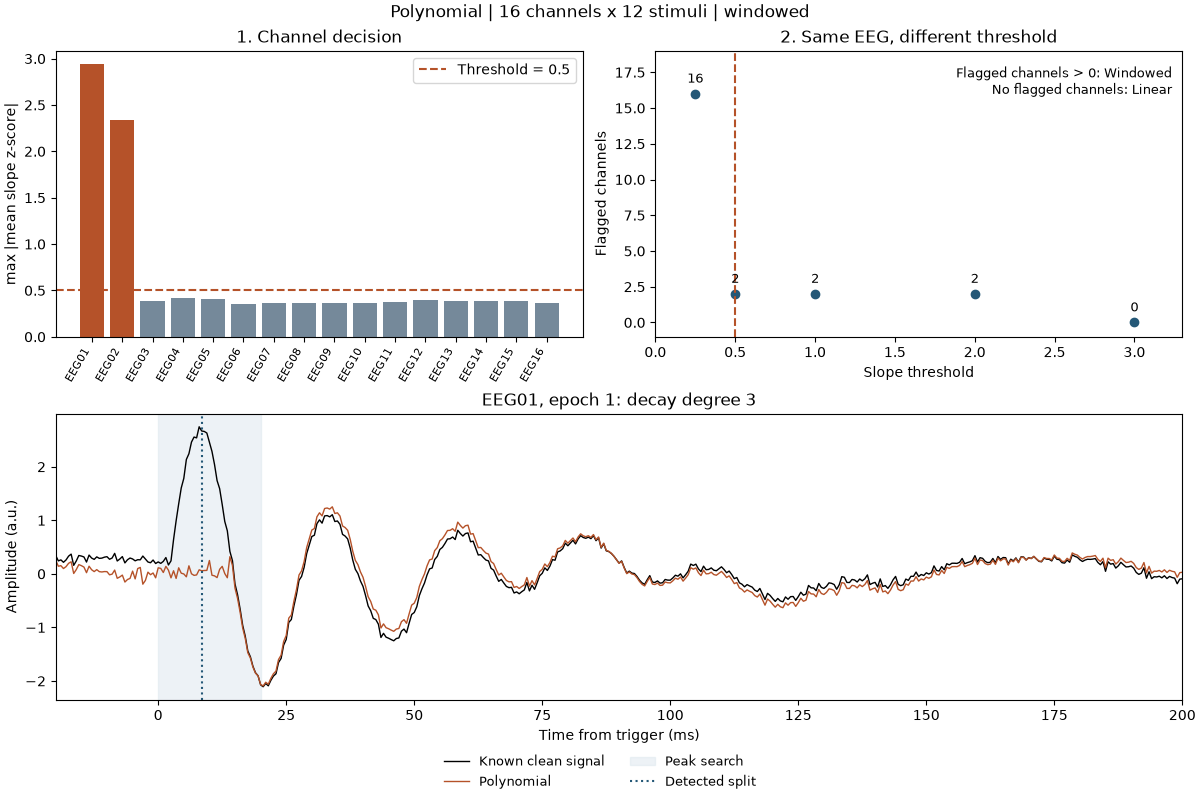

In [6]:
fig = plt.figure(figsize=(12, 8), layout='constrained')
grid = fig.add_gridspec(2, 2)
ax_scores = fig.add_subplot(grid[0, 0])
ax_sweep = fig.add_subplot(grid[0, 1])
ax_wave = fig.add_subplot(grid[1, :])
colors = ['#b55229' if c in offset_channels else '#75899a' for c in range(toy['n_channels'])]
ax = ax_scores
ax.bar(np.arange(toy['n_channels']), scores, color=colors)
ax.axhline(cfg.slope_threshold, color='#b55229', ls='--', label=f'Threshold = {cfg.slope_threshold:g}')
ax.set_xticks(np.arange(toy['n_channels']), labels, rotation=60, ha='right', fontsize=8)
ax.set_ylabel('max |mean slope z-score|'); ax.set_title('1. Channel decision'); ax.legend()
ax = ax_sweep
ax.plot(sweep_thresholds, sweep_counts, 'o', color='#245877')
for x, count in zip(sweep_thresholds, sweep_counts):
    ax.annotate(str(count), (x,count), xytext=(0,8), textcoords='offset points', ha='center', fontsize=9)
ax.axvline(cfg.slope_threshold, color='#b55229', ls='--')
ax.set(xlabel='Slope threshold', ylabel='Flagged channels', ylim=(-1,toy['n_channels']+3),
       xlim=(0,float(sweep_thresholds[-1])+.3), title='2. Same EEG, different threshold')
ax.text(.98,.95,'Flagged channels > 0: Windowed\nNo flagged channels: Linear',
        transform=ax.transAxes,ha='right',va='top',fontsize=9)
display_epoch = 0  # One epoch, not an average; MATLAB uses index 1 for this epoch.
display_channel = int(np.argmax(scores))
ax = ax_wave; c = display_channel; e = display_epoch
ax.plot(times*1000, truth[e,c], color='black', lw=1, label='Known clean signal')
ax.plot(times*1000, corrected[e,c], color='#b55229', lw=1, label='Polynomial')
ax.axvspan(cfg.onset_s*1000,cfg.peak_search_end_s*1000,color='#dce7ee',alpha=.5,label='Peak search')
rec = next((r for r in diagnostics['fits'] if r['epoch']==e and r['channel']==c), None)
if rec and 'peak_s' in rec:
    ax.axvline(1000*rec['peak_s'],color='#245877',ls=':',label='Detected split')
    subtitle=f'decay degree {rec["decay"]["degree"]}'
else:
    subtitle='whole-epoch linear'
ax.set(title=f'{labels[c]}, epoch {e+1}: {subtitle}',xlabel='Time from trigger (ms)',
       ylabel='Amplitude (a.u.)',xlim=(-20,200))
fig.legend(*ax_wave.get_legend_handles_labels(), loc='outside lower center',
           ncol=2, fontsize=9, frameon=False)
fig.suptitle(f'Polynomial | {toy["n_channels"]} channels x {toy["n_epochs"]} stimuli | {operation}')

## 4. Butterfly view: before and after correction


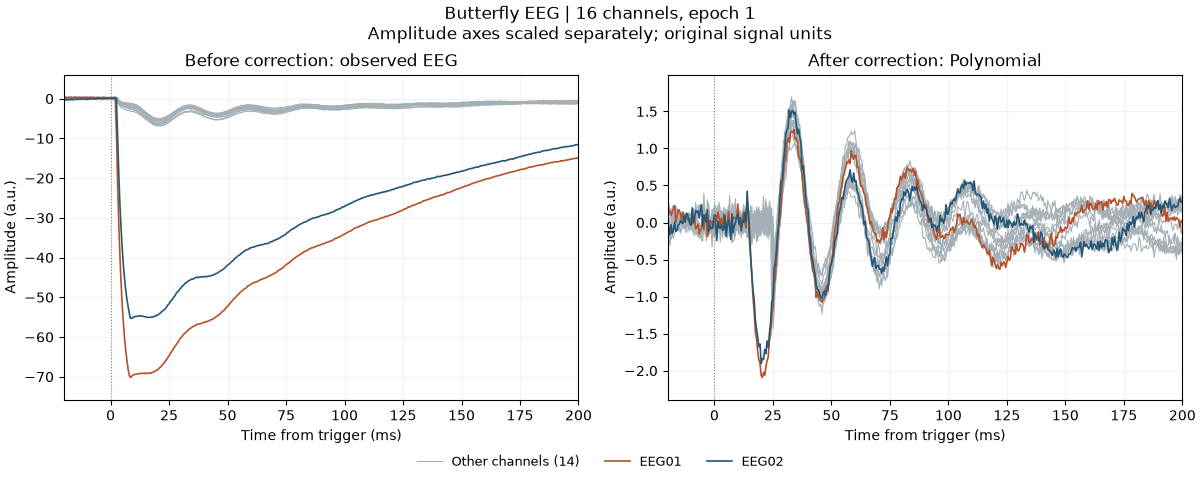

In [7]:
# Both panels show ALL channels from the SAME epoch, with the same colors.
# Highlight the two strongest simulated artifacts, independently of screening.
# This is a display-only use of synthetic metadata; it does not affect fitting.
highlight_channels = np.argsort(np.mean(np.abs(metadata['artifact_gains']),axis=0))[-2:][::-1].tolist()
other_channels = [c for c in range(toy['n_channels']) if c not in highlight_channels]
highlight_colors = ['#b55229', '#245877']
display_mask = (times >= -.020) & (times <= .200)
fig_butterfly, axes_butterfly = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, layout='constrained')
for ax, values, heading in zip(axes_butterfly, (data, corrected),
                                ('Before correction: observed EEG', 'After correction: Polynomial')):
    for j, c in enumerate(other_channels):
        ax.plot(times*1000, values[display_epoch,c], color='#a5afb6', lw=.8,
                label=f'Other channels ({len(other_channels)})' if j==0 else None)
    for c, color in zip(highlight_channels,highlight_colors):
        ax.plot(times*1000, values[display_epoch,c], color=color, lw=1.2, label=labels[c])
    ax.axvline(0,color='#75899a',ls=':',lw=.8)
    visible = values[display_epoch][:,display_mask]
    lower,upper = float(visible.min()),float(visible.max())
    pad = .08*max(upper-lower,1e-12)
    ax.set(title=heading,xlabel='Time from trigger (ms)',ylabel='Amplitude (a.u.)',
           xlim=(-20,200),ylim=(lower-pad,upper+pad))
    ax.grid(alpha=.15)
fig_butterfly.legend(*axes_butterfly[0].get_legend_handles_labels(), loc='outside lower center',
                     ncol=3, fontsize=9, frameon=False)
fig_butterfly.suptitle(f'Butterfly EEG | {toy["n_channels"]} channels, epoch {display_epoch+1}\n'
                      'Amplitude axes scaled separately; original signal units')
plt.show()

## 5. Continue the host pipeline


In [8]:
# Replace data/times with real preprocessed epochs; keep matching good EEG
# channels in MATLAB and Python because screening depends on that population.
# Gaussian filling remains enabled; inspect diagnostics, then continue ICA.
data_for_ica = corrected